# Exploring MassSave data on Air-source Heat Pumps (ASHPs)

This notebook contains a simple exploratory data analysis of MassSave upfront costs data for ASHPs.

#### Setup

In [0]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [0]:
dbutils.widgets.dropdown(
    "mode", "feature", ["feature", "develop", "main", "hotfix"]
)  # mode to read/write delta tables in (see `util.modify_db_table_name()`)
MODE = dbutils.widgets.get("mode")

#### Load data

In [0]:
# Load processed mass wholehome data
mass_wholehome = spark.table("processed.upfront_costs.mass_wholehome")
# Drop columns with void types
mass_wholehome = mass_wholehome.drop(
    "manufacture_of_outdoor_unit_number6",
    "model_of_outdoor_unit_number6",
    "ahri_number_of_outdoor_unit_number6",
    "outdoor_unit_number6_capacity_at_design_temperature_btu_hr",
    "are_you_applying_for_the_blower_door_test_rebate_adder",
)

# Load processed mass Residential ASHP program data
mass_ashp = spark.table("processed.upfront_costs.mass_ashp")
# Drop columns with void types
mass_ashp = mass_ashp.drop("unnamed:_47")

In [0]:
# Convert to pandas
# MassSave (Whole Home data)
mass_wholehome = mass_wholehome.toPandas()
print(f"MassSave (Whole Home): {mass_wholehome.shape[0]} rows")

mass_ashp = mass_ashp.toPandas()
print(f"MassSave (ASHP): {mass_ashp.shape[0]} rows")

MassSave (Whole Home): 156 rows
MassSave (ASHP): 20074 rows


In [0]:
# Let's winsorize to control for the effects of outliers
lower = mass_ashp["project_cost_raw"].quantile(0.001)
upper = mass_ashp["project_cost_raw"].quantile(0.999)
mass_ashp["project_cost_raw"] = np.clip(mass_ashp["project_cost_raw"], lower, upper)

In [0]:
mass_ashp["number_units_number_of_outdoor_units"] = mass_ashp["number_units_number_of_outdoor_units"].astype(int)
mass_ashp["equipment_costs"] = pd.to_numeric(mass_ashp["equipment_costs"], errors="coerce")

In [0]:
mass_ashp["total_number_of_indoor_units"] = pd.to_numeric(
    mass_ashp["total_number_of_indoor_units"].apply(
        lambda x: (
            "0"
            if x == "-"
            else (
                "1"
                if x in ["one", "One", "one (1)"]
                else "2" if x in ["Two", "two"] else "4" if x == "four" else "" if x in ["17614", "42673"] else x
            )
        )
    ),
    errors="coerce",
)

#### Explore
Let's focus on `mass_ashp` due to the relatively low number of records from the wholehome program.

Data quality: there are many categorical columns in `mass_ashp` with messy data entry:

In [0]:
mass_ashp["utility"].value_counts().head(15)

Eversource                        11485
National Grid                      7475
Unitil                              384
EVERSOURCE                          232
NGRIDMA                             103
eversource                           59
Eversource                           59
Holyoke MLP                          46
Municipal Electric Departments       46
national grid                        33
Holden MLP                           33
Templeton MLP                        26
NATIONAL GRID                        22
Ashburnham MLP                       10
National grid                         9
Name: utility, dtype: int64

In [0]:
mass_ashp["current_heating_fuel"].value_counts().head(15)

Natural Gas            7602
Oil                    7268
Electric Resistance    2387
Propane                 470
Propane                 468
None                    422
Other                   263
Woodstove               189
oil                     151
Electric                128
Pellet Stove            112
Natural Gas              52
natural gas              32
OIL                      24
Heat Pump                19
Name: current_heating_fuel, dtype: int64

In [0]:
mass_ashp["current_a_c"].value_counts().head(15)

Window Unit(s)         8074
None                   3492
2 window units         1755
3+ window units        1601
1 window unit           952
Centralized System      823
Other                   499
Existing heat pumps     329
Centralized system      312
Ceiling Fan             234
Ceiling fan             125
Window Fan              102
none                     88
Existing Heat Pumps      66
Window fan               61
Name: current_a_c, dtype: int64

What does the project cost distribution look like?

<Axes: xlabel='project_cost_raw', ylabel='Density'>

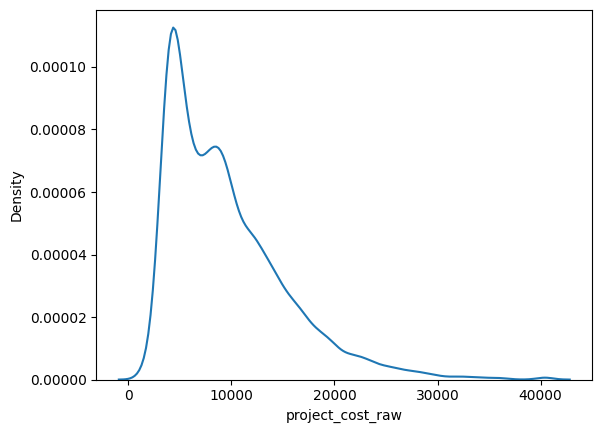

In [0]:
fig, ax = plt.subplots()
sns.kdeplot(mass_ashp["project_cost_raw"], ax=ax)

In [0]:
mass_ashp.groupby("heat_pump_type").agg(
    mean_cost=pd.NamedAgg("project_cost_raw", "mean"),
    mean_capacity=pd.NamedAgg("heating_capacity_tons", "mean"),
    count=pd.NamedAgg("heat_pump_type", "count"),
)

,mean_cost,mean_capacity,count
heat_pump_type,,,
Partial,11806.668233,2.883826,9063
Single Zone,5153.591635,1.427783,8038
Whole Home,14506.895349,3.834935,2973


When and where did these installations occur?

(array([ 585., 1790., 1360., 2512., 1576., 3354., 1950., 4247., 2689.,
          11.]),
 array([16413. , 16594.1, 16775.2, 16956.3, 17137.4, 17318.5, 17499.6,
        17680.7, 17861.8, 18042.9, 18224. ]),
 <BarContainer object of 10 artists>)

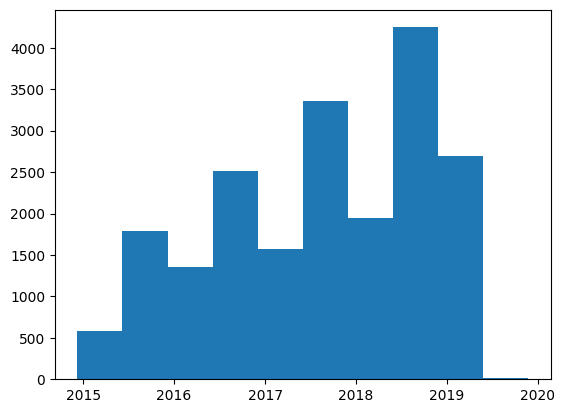

In [0]:
mass_ashp["start_date"] = pd.to_datetime(mass_ashp["start_date"], format="%m/%d/%y")
mass_ashp["date_of_installation"] = pd.to_datetime(
    mass_ashp["date_of_installation"], format="%m/%d/%y", errors="coerce"
)
fig, ax = plt.subplots()
ax.hist(mass_ashp["start_date"])

In [0]:
mass_ashp["project_town"].str.lower().value_counts().head(10)

plymouth       339
amherst        281
brewster       266
worcester      242
boston         217
leominster     211
greenfield     208
framingham     207
easthampton    202
arlington      186
Name: project_town, dtype: int64

What do the rebates look like?

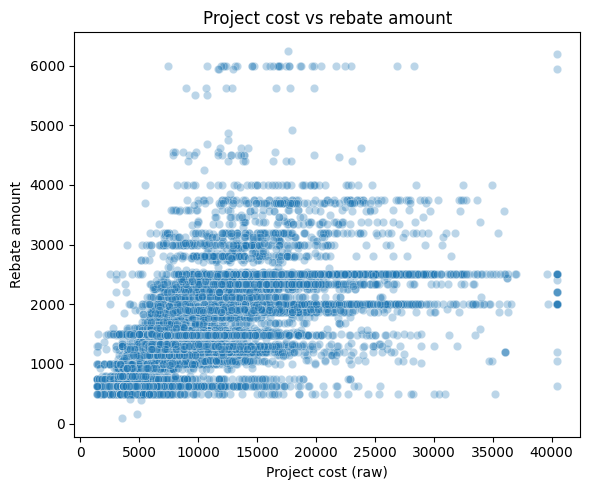

In [0]:
mass_ashp["rebate_amount_dollars"] = pd.to_numeric(mass_ashp["rebate_amount_dollars"], errors="coerce")

plt.figure(figsize=(6, 5))
sns.scatterplot(data=mass_ashp, x="project_cost_raw", y="rebate_amount_dollars", alpha=0.3)
plt.title("Project cost vs rebate amount")
plt.ylabel("Rebate amount")
plt.xlabel("Project cost (raw)")
plt.tight_layout()
plt.show()

There are a small number of potentially important features we currently expect to be able to get in other
datasets and future prediction contexts. Let's look into these:

In [0]:
mass_ashp[["project_cost_raw", "square_footage", "heating_capacity_tons", "seer", "hspf_region_iv"]].describe()

,project_cost_raw,square_footage,heating_capacity_tons,seer,hspf_region_iv
count,20031.000000,20034.000000,20073.000000,20074.000000,20074.000000
mean,9547.064833,1924.325746,2.441639,21.879730,11.436789
std,5708.628041,1346.568810,1.183252,4.021664,1.152803
min,1450.750000,0.000000,0.580667,17.000000,10.000000
25%,4980.000000,1360.000000,1.542000,19.000000,10.300000
50%,8290.000000,1800.000000,2.125000,20.300000,11.300000
75%,12477.430000,2300.000000,3.033917,25.300000,12.000000
max,40455.000000,91936.000000,12.000000,33.100000,14.200000


Let's look at correlations.

In [0]:
mass_ashp[["project_cost_raw", "square_footage", "heating_capacity_tons", "seer", "hspf_region_iv"]].corr()

,project_cost_raw,square_footage,heating_capacity_tons,seer,hspf_region_iv
project_cost_raw,1.000000,0.105633,0.775048,-0.446727,-0.405734
square_footage,0.105633,1.000000,0.104564,-0.031599,-0.019297
heating_capacity_tons,0.775048,0.104564,1.000000,-0.419760,-0.361239
seer,-0.446727,-0.031599,-0.419760,1.000000,0.805038
hspf_region_iv,-0.405734,-0.019297,-0.361239,0.805038,1.000000


We can see:
- A strong correlation between heating capacity and project cost
- Strong correlation between SEER and HSPF
- Interestingly, weak negative correlations between SEER and project cost, and HSPF and project cost -
though this looks to be largely a explained by the relationship between SEER/HSPF and heating capacity:
as heating capacity increases, generally SEER and HSPF decrease.

We generally see the same patterns in the wholehome data, though with weaker correlations.

In [0]:
mass_wholehome[["project_cost_raw", "square_footage", "heating_capacity_tons", "seer", "hspf_region_iv"]].corr()

,project_cost_raw,square_footage,heating_capacity_tons,seer,hspf_region_iv
project_cost_raw,1.000000,0.541840,0.535868,-0.229778,-0.111027
square_footage,0.541840,1.000000,0.625894,-0.003530,0.020857
heating_capacity_tons,0.535868,0.625894,1.000000,-0.204610,-0.083105
seer,-0.229778,-0.003530,-0.204610,1.000000,0.794886
hspf_region_iv,-0.111027,0.020857,-0.083105,0.794886,1.000000


Let's visualize:

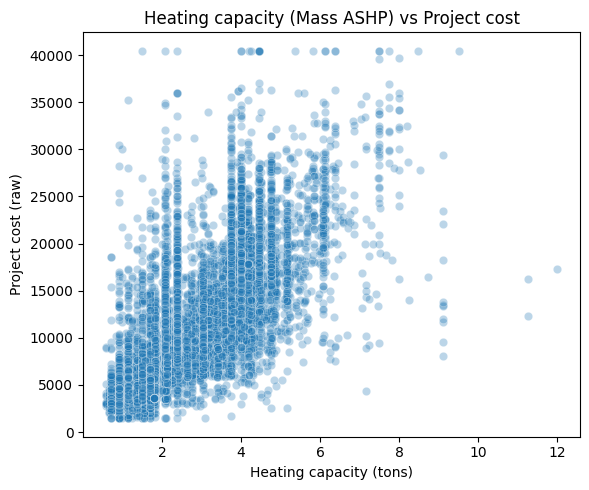

In [0]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=mass_ashp, x="heating_capacity_tons", y="project_cost_raw", alpha=0.3)
plt.title("Heating capacity (Mass ASHP) vs Project cost")
plt.xlabel("Heating capacity (tons)")
plt.ylabel("Project cost (raw)")
plt.tight_layout()
plt.show()

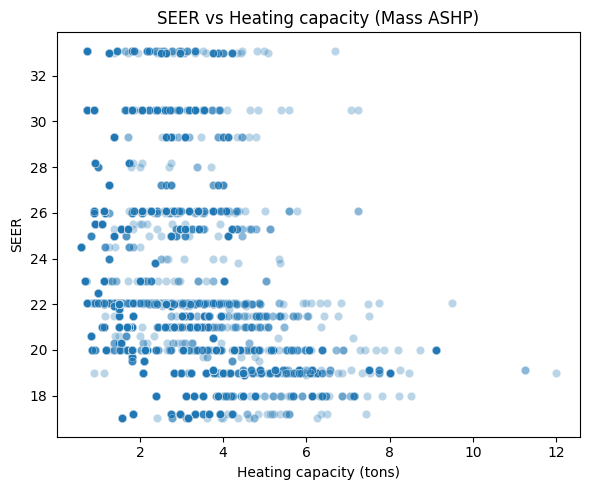

In [0]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=mass_ashp, x="heating_capacity_tons", y="seer", alpha=0.3)
plt.title("SEER vs Heating capacity (Mass ASHP)")
plt.xlabel("Heating capacity (tons)")
plt.ylabel("SEER")
plt.tight_layout()
plt.show()

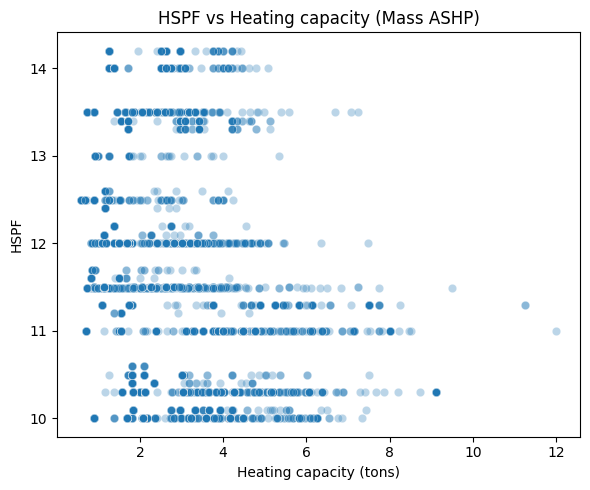

In [0]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=mass_ashp, x="heating_capacity_tons", y="hspf_region_iv", alpha=0.3)
plt.title("HSPF vs Heating capacity (Mass ASHP)")
plt.xlabel("Heating capacity (tons)")
plt.ylabel("HSPF")
plt.tight_layout()
plt.show()

If we control for heating capacity, can we intuitively see what explains the remaining variation?

2338


<Axes: xlabel='project_cost_raw', ylabel='Density'>

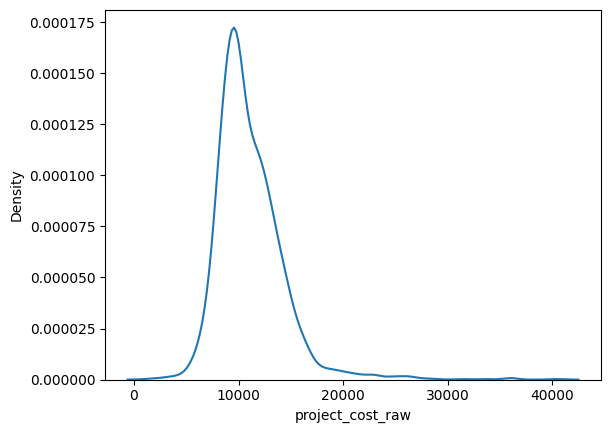

In [0]:
# Choose a set of ~2,000 installations of roughly equivalent heating capacity
mass_ashp_standard_size = mass_ashp[(np.abs(mass_ashp["heating_capacity_tons"] - 2.383333) < 0.001)]
print(mass_ashp_standard_size.shape[0])
sns.kdeplot(mass_ashp_standard_size["project_cost_raw"])

In [0]:
mass_ashp_standard_size[["project_cost_raw", "square_footage", "seer", "hspf_region_iv"]].corr()

,project_cost_raw,square_footage,seer,hspf_region_iv
project_cost_raw,1.000000,0.017221,0.098721,0.077720
square_footage,0.017221,1.000000,0.015228,0.022082
seer,0.098721,0.015228,1.000000,0.848058
hspf_region_iv,0.077720,0.022082,0.848058,1.000000


It looks like there is meaningful variation after controlling for heating capacity, and it is not well-explained by our other variables "of interest". What if we control further by installer?

In [0]:
mass_ashp_standard_size[
    (mass_ashp_standard_size["primary_installer_company_name"].str.strip() == "NETR LLC")
    & (mass_ashp_standard_size["project_cost_raw"] > 15000)
][
    [
        "square_footage",
        "current_heating_fuel",
        "total_number_of_indoor_units",
        "number_units_number_of_outdoor_units",
        "seer_multi",
        "hspf_multi",
        "project_cost_raw",
    ]
].sample(
    5, random_state=30
)

,square_footage,current_heating_fuel,total_number_of_indoor_units,number_units_number_of_outdoor_units,seer_multi,hspf_multi,project_cost_raw
645,917.0,Oil,0.0,1,18.0,11.0,15697.0
13218,1550.0,Natural Gas,3.0,1,18.0,11.0,16655.0
13519,1192.0,Electric Resistance,3.0,1,18.0,11.0,20401.0
17591,906.0,Natural Gas,3.0,1,18.0,11.0,16963.0
10920,1100.0,Natural Gas,3.0,1,18.0,11.0,15367.0


In [0]:
mass_ashp_standard_size[
    (mass_ashp_standard_size["primary_installer_company_name"].str.strip() == "NETR LLC")
    & (mass_ashp_standard_size["project_cost_raw"] < 10000)
][
    [
        "square_footage",
        "current_heating_fuel",
        "total_number_of_indoor_units",
        "number_units_number_of_outdoor_units",
        "seer_multi",
        "hspf_multi",
        "project_cost_raw",
    ]
].sample(
    5, random_state=30
)

,square_footage,current_heating_fuel,total_number_of_indoor_units,number_units_number_of_outdoor_units,seer_multi,hspf_multi,project_cost_raw
15298,1200.0,Electric Resistance,NaN,2,18.0,11.0,9963.0
4231,1290.0,Oil,2.0,1,18.0,11.0,6196.0
9787,1500.0,natural gas,NaN,1,18.0,11.0,7125.0
481,3440.0,Natural Gas,0.0,1,18.0,11.0,9487.0
19687,1800.0,Natural Gas,2.0,1,18.0,11.0,9500.0


Here we can see multiple installations with equal heating capacities, very similar attributes, with the same installer, and still a huge range in costs. It seems there is still important information that we're missing.